# WEB-02: Explore FIT file data
**Garmin Watch project · Web Development stream**

Goal: find out what data is inside the Garmin FIT files, so we know what the web dashboard can show and store.

Files used: the 3 sample runs in the repo's TestingData folder

In [ ]:
!git clone -q --depth 1 https://github.com/Redback-Operations/garmin-smartwatch.git
!pip install -q fitparse

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
import os, json
from google.colab import drive
drive.mount('/content/drive')

OUT = "/content/drive/MyDrive/capstone_project"
os.makedirs(OUT, exist_ok=True)

Mounted at /content/drive


In [ ]:
import os, glob
print("Current folder:", os.getcwd())
print("Repo downloaded?", os.path.exists("/content/garmin-smartwatch"))
print(glob.glob("/content/garmin-smartwatch/TestingData/*"))

Current folder: /content
Repo downloaded? True
['/content/garmin-smartwatch/TestingData/brave_OVpZoUQqRg.png', '/content/garmin-smartwatch/TestingData/brave_DspsWicr2a.png', '/content/garmin-smartwatch/TestingData/brave_J3y1v2oCIF.png', '/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit', '/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit', '/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit']


In [ ]:
import glob
import fitparse
import pandas as pd
import matplotlib.pyplot as plt

files = sorted(glob.glob("/content/garmin-smartwatch/TestingData/*.fit"))
print(len(files), "files found")
files

3 files found


['/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit',
 '/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit',
 '/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit']

| Section | Contents |
|---|---|
| `record` | Real-time data, consisting of hundreds of rows |
| `session` | Summary of the entire run |
| `lap` | Summary of each lap |
| `user_profile` | Runner's height and weight |
| `file_id` | Watch model and serial number |

In [ ]:
# The types of information we want to count in each file
types_we_want = ["record", "session", "lap", "user_profile", "file_id"]

# Go through each of the 3 FIT files
for file_path in files:
    fit_file = fitparse.FitFile(file_path)
    counts = {}
    for message_type in types_we_want:
        counts[message_type] = 0

    # Go through every message in the file
    for message in fit_file.get_messages():
        if message.name in types_we_want:
            counts[message.name] = counts[message.name] + 1
    print(file_path, "->", counts)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit -> {'record': 378, 'session': 1, 'lap': 5, 'user_profile': 1, 'file_id': 1}
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit -> {'record': 1266, 'session': 1, 'lap': 16, 'user_profile': 1, 'file_id': 1}
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit -> {'record': 1283, 'session': 1, 'lap': 14, 'user_profile': 1, 'file_id': 1}


In [ ]:
def read_records(file_path):
    fit_file = fitparse.FitFile(file_path)
    rows = []

    # Go through every 'record' message (the moment-by-moment data)
    for record in fit_file.get_messages("record"):
        row = {}
        for field in record:
            row[field.name] = field.value
        rows.append(row)

    table = pd.DataFrame(rows)
    return table


first_run = read_records(files[0])
first_run.head()

,cadence,distance,enhanced_altitude,enhanced_speed,fractional_cadence,heart_rate,position_lat,position_long,temperature,timestamp,unknown_136,unknown_88
0,0,2.00,640.2,0.000,0.0,84,-426838148.0,1.765824e+09,29,2023-10-20 07:49:36,84,100
1,0,4.08,640.2,0.000,0.0,85,-426838192.0,1.765825e+09,29,2023-10-20 07:49:37,85,100
2,78,6.16,640.2,0.998,0.5,91,-426838212.0,1.765825e+09,29,2023-10-20 07:49:38,91,100
3,80,9.08,640.2,1.092,0.0,90,-426838247.0,1.765825e+09,29,2023-10-20 07:49:39,90,100
4,80,16.12,640.0,3.070,0.0,92,-426838288.0,1.765826e+09,28,2023-10-20 07:49:41,92,100


In [ ]:
for file_path in files:
    run_table = read_records(file_path)
    useful_columns = []
    for column_name in run_table.columns:
        # Skip columns called "unknown..."
        if column_name.startswith("unknown"):
            continue
        useful_columns.append(column_name)
    print(file_path, useful_columns)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit ['cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'temperature', 'timestamp']
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit ['cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'temperature', 'timestamp']
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit ['altitude', 'cadence', 'distance', 'enhanced_altitude', 'enhanced_speed', 'fractional_cadence', 'heart_rate', 'position_lat', 'position_long', 'speed', 'timestamp']


In [ ]:
# The three running dynamics:
# step_length          = stride length
# vertical_oscillation = how much the body moves up and down
# stance_time          = ground contact time
running_dynamics = ["step_length", "vertical_oscillation", "stance_time"]

for file_path in files:
    run_table = read_records(file_path)
    results = {}
    for metric in running_dynamics:
        if metric in run_table.columns:
            results[metric] = True
        else:
            results[metric] = False
    print(file_path, results)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit {'step_length': False, 'vertical_oscillation': False, 'stance_time': False}


In [ ]:
import statistics

for file_path in files:
    run_table = read_records(file_path)
    times = list(run_table["timestamp"])

    # Work out the gap (in seconds) between each saved row and the one before it
    gaps = []
    for i in range(1, len(times)):
        gap = times[i] - times[i - 1]
        gaps.append(gap.total_seconds())

    # The usual gap (median) and the biggest gap
    usual_gap = statistics.median(gaps)
    biggest_gap = max(gaps)

    print(file_path, "| usual gap:", usual_gap, "s | biggest gap:", biggest_gap, "s")

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit median gap: 3.0 s | max gap: 27.0 s
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit median gap: 4.0 s | max gap: 410.0 s
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit median gap: 7.0 s | max gap: 18.0 s


**Run summary**

Garmin stores cadence as strides per minute, so we multiply by 2 to get steps per minute (spm).

In [ ]:
def run_summary(path):
    ff = fitparse.FitFile(path)
    s = {d.name: d.value for d in next(ff.get_messages("session"))}
    u = {d.name: d.value for d in next(fitparse.FitFile(path).get_messages("user_profile"))}
    dev = {d.name: d.value for d in next(fitparse.FitFile(path).get_messages("file_id"))}
    avg_cad = (s["avg_running_cadence"] + (s.get("avg_fractional_cadence") or 0)) * 2
    return {
        "file": path.split("/")[-1],
        "device": dev.get("garmin_product"),
        "start_time": s["start_time"],
        "duration_min": round(s["total_timer_time"] / 60, 1),
        "distance_km": round(s["total_distance"] / 1000, 2),
        "avg_cadence_spm": round(avg_cad),
        "max_cadence_spm": s["max_running_cadence"] * 2,
        "avg_hr_bpm": s["avg_heart_rate"],
        "avg_pace_min_km": round((s["total_timer_time"] / 60) / (s["total_distance"] / 1000), 2),
        "height_m": u.get("height"),
        "weight_kg": u.get("weight"),
    }

summary = pd.DataFrame([run_summary(f) for f in files])
summary

,file,device,start_time,duration_min,distance_km,avg_cadence_spm,max_cadence_spm,avg_hr_bpm,avg_pace_min_km,height_m,weight_kg
0,12391773953_ACTIVITY.fit,3126,2023-10-20 07:49:36,20.7,4.03,154,178,162,5.15,1.81,90.0
1,12974552018_ACTIVITY.fit,3126,2023-12-04 04:36:29,87.7,15.57,153,160,161,5.63,1.81,90.0
2,1591601608_ACTIVITY.fit,vivo_active_hr,2017-02-25 19:45:50,121.2,21.15,156,164,159,5.73,1.80,93.0


Check: per-record cadence vs the watch's own average

In [ ]:
# Check is our own cadence calculation close to the watch's average?
for file_path in files:

    run_table = read_records(file_path)
    moving_cadences = []
    for index, row in run_table.iterrows():

        # Skip moments when the runner is stopped (speed of 1 m/s or less)
        if row["enhanced_speed"] <= 1.0:
            continue

        # cadence has two parts a whole number and a fraction
        fraction = row["fractional_cadence"]
        if pd.isna(fraction):
            fraction = 0

        # multiply counts by 2 to get 2 steps per minute
        steps_per_minute = (row["cadence"] + fraction) * 2
        moving_cadences.append(steps_per_minute)

    # Work out the average
    average_cadence = sum(moving_cadences) / len(moving_cadences)

    print(file_path, "| our average cadence:", round(average_cadence), "spm")

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit average of records: 156 spm
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit average of records: 154 spm
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit average of records: 156 spm


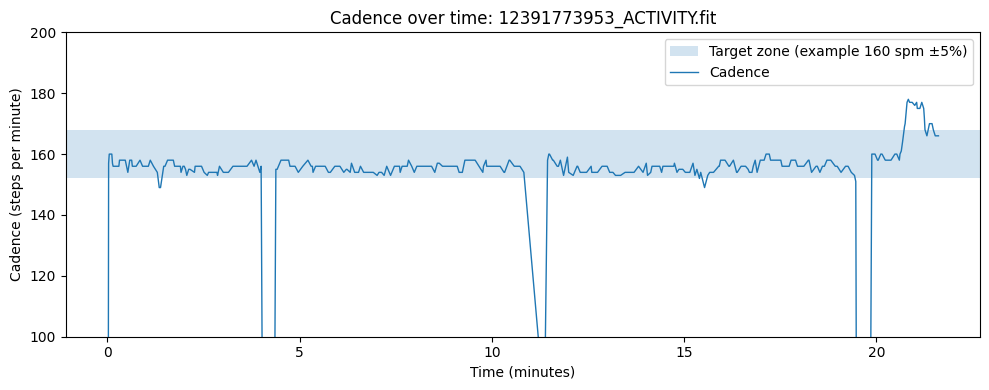

Time in target zone (while moving): 92%


In [ ]:
r = read_records(files[0])
r["spm"] = (r["cadence"] + r["fractional_cadence"].fillna(0)) * 2
r["minutes"] = (r["timestamp"] - r["timestamp"].iloc[0]).dt.total_seconds() / 60

target = 160          # example target cadence
low, high = target * 0.95, target * 1.05

plt.figure(figsize=(10, 4))
plt.axhspan(low, high, alpha=0.2, label="Target zone (example 160 spm ±5%)")
plt.plot(r["minutes"], r["spm"], linewidth=1, label="Cadence")
plt.xlabel("Time (minutes)")
plt.ylabel("Cadence (steps per minute)")
plt.title("Cadence over time: " + files[0].split("/")[-1])
plt.ylim(100, 200)
plt.legend()
plt.tight_layout()
plt.savefig("cadence_over_time.png", dpi=120)
plt.show()

moving = r[r["enhanced_speed"] > 1.0]   # ignore stops, where cadence drops to 0
in_zone = moving["spm"].between(low, high).mean() * 100
print(f"Time in target zone (while moving): {in_zone:.0f}%")

These fields could identify a runner and must **not** be stored.

In [ ]:
# Privacy check: does each file contain information that could identify a runner?
for file_path in files:
    run_table = read_records(file_path)

    # 1. Check for GPS location
    if "position_lat" in run_table.columns:
        has_gps = True
    else:
        has_gps = False

    # 2. Check for the watch serial number
    fit_file = fitparse.FitFile(file_path)
    has_serial_number = False
    for message in fit_file.get_messages("file_id"):
        for field in message:
            if field.name == "serial_number" and field.value is not None:
                has_serial_number = True

    print(file_path, "| GPS:", has_gps, "| serial number:", has_serial_number)

/content/garmin-smartwatch/TestingData/12391773953_ACTIVITY.fit | GPS: True | serial number: True
/content/garmin-smartwatch/TestingData/12974552018_ACTIVITY.fit | GPS: True | serial number: True
/content/garmin-smartwatch/TestingData/1591601608_ACTIVITY.fit | GPS: True | serial number: True


## Findings
1. **Cadence** is saved for one foot, so multiply by 2 for steps per minute.
2. **Running dynamics** (stride length, vertical oscillation, ground contact time) are **not** in the sample files. We need a new test file.
3. Data is saved every **3 to 7 seconds**, not every second.
4. When the runner stops, cadence drops to **0**. Ignore these points in averages and % in zone.
5. **Height and weight** are in the file, so they can go in the CSV export.
6. No runner **name** was found, but **GPS** and the watch **serial number** are there, so both must be removed.
7. Target cadence and feedback visible/hidden are **not** in the files yet. They will come from Nick's WCH-13.